<img width="200" style="float:left" 
     src="https://upload.wikimedia.org/wikipedia/commons/f/f3/Apache_Spark_logo.svg" />

# Lab 18.1 — Apache Spark SQL API, TfL Bike Point Analysis + SQL Lab

This notebook is organized in the following sections:

# Sections
* [Description](#0)
* [Notebook environment setup](#1)
  * [MinIO start up](#1.1)  
* [Step 1 - Create DataFrame with Bike points information for current month](#2)
  * [DataFrame creation](#2.1)
  * [Shaping the DataFrame to answer business questions](#2.2)
* [Step 2 - Temporary view creation](#3)
  * [Temporary view SQL manipulation](#3.1)
  * [DataFrame from results after temporary view manipulation](#3.2)
  * [SQL challenge with Spark SQL](#3.3)
* [Environment shutdown](#4)

<a id='0'></a>
## Description
This notebook complements the lecture *"Apache Spark - SQL API"* and we'll see **different ways of leveraging SQL within our Spark applications**.

This notebook will show you how to:

1. **Create a temporary view** from a [DataFrame](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.html)
2. **Manipulate temporary views** via SQL statements
3. **Create [DataFrames](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.html)** as the *result of temporary view manipulation*

We're going to reuse part of the Spark analysis we did in the Jupyter notebook ***Transport for London - Bike point analysis***, therefore *you should be familiar with most of the Spark code we'll use*.

<a id='1'></a>
## Notebook environment setup
Create a folder named `/mda1/sql_api` in your Jupyter Notebook environment and place all the files used throughout this exercise inside it. Keeping everything organized in a single location will make it easier to follow the examples and better understand each step of the process:

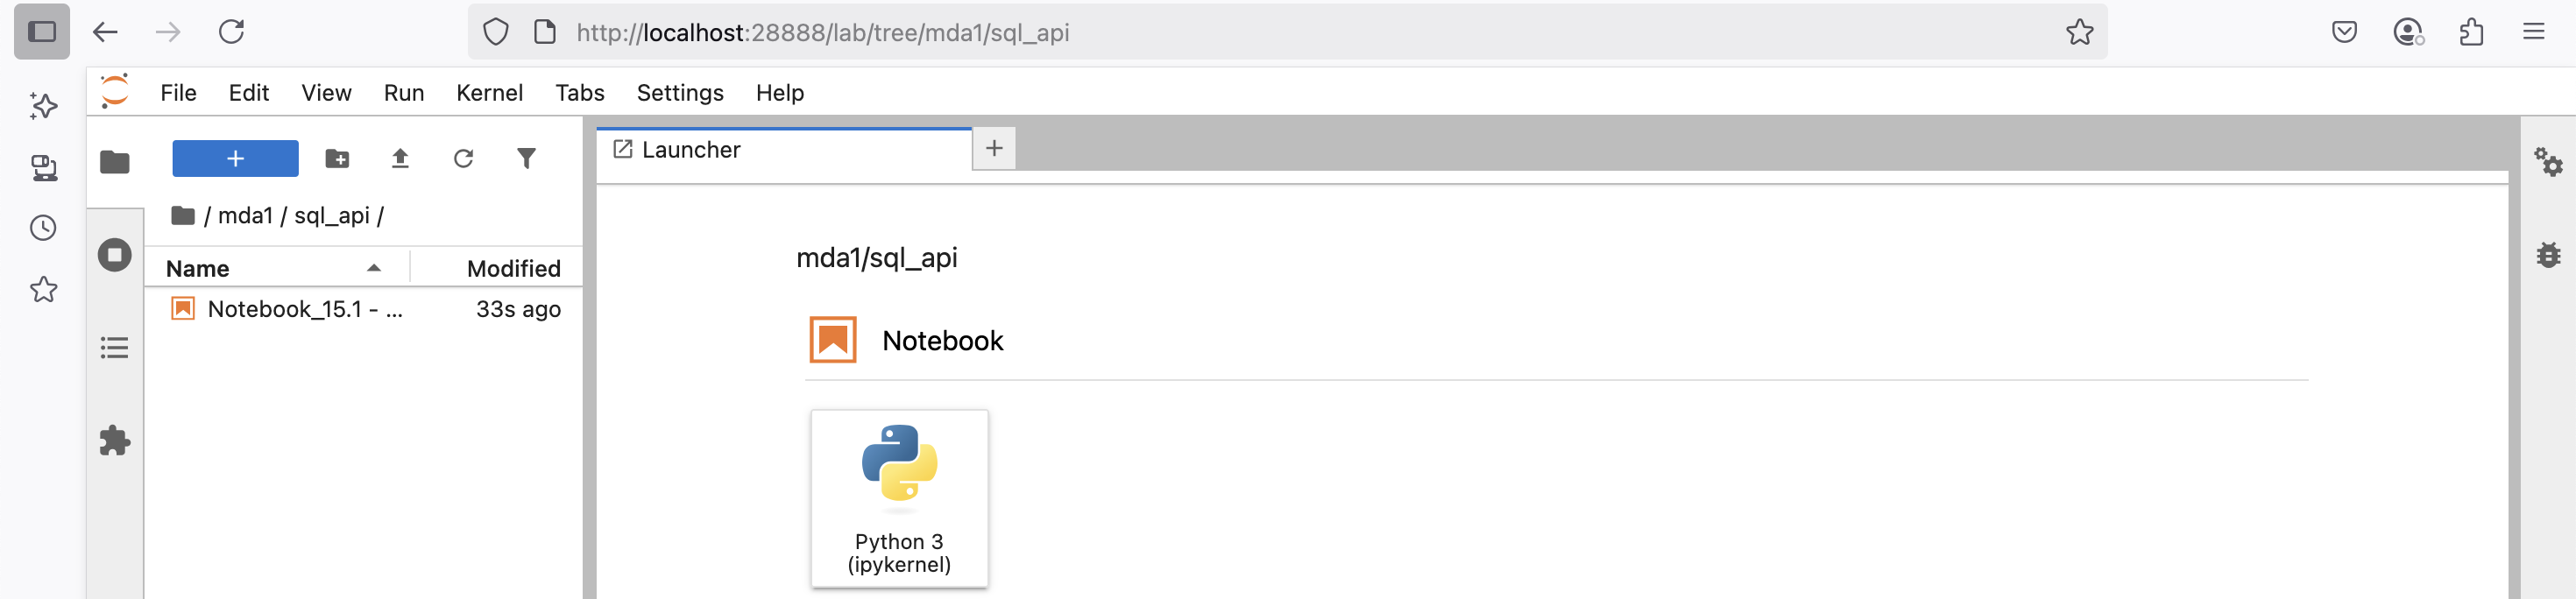

We will use **Pandas** to **display the results in a more readable format**, so let's configure it first:

In [ ]:
import pandas as pd

pd.set_option('display.max_colwidth', None)

Now it's **time to create the [Spark Session](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.SparkSession.html)** before we can do anything else. Remember, the Spark Session *is the entry point for working with Spark through the DataFrame API (the high-level API)*.

In [ ]:
from pyspark.sql.session import SparkSession

spark_session = \
  SparkSession.builder\
              .appName("Apache Spark - SQL API + Lab")\
              .getOrCreate()

print(f"This cluster relies on Spark '{spark_session.version}'")

<a id='1.1'></a>
### MinIO start up
Let’s **start MinIO and make it available** by turning them on from the [OSBDET's Web UI](http://localhost:2026):

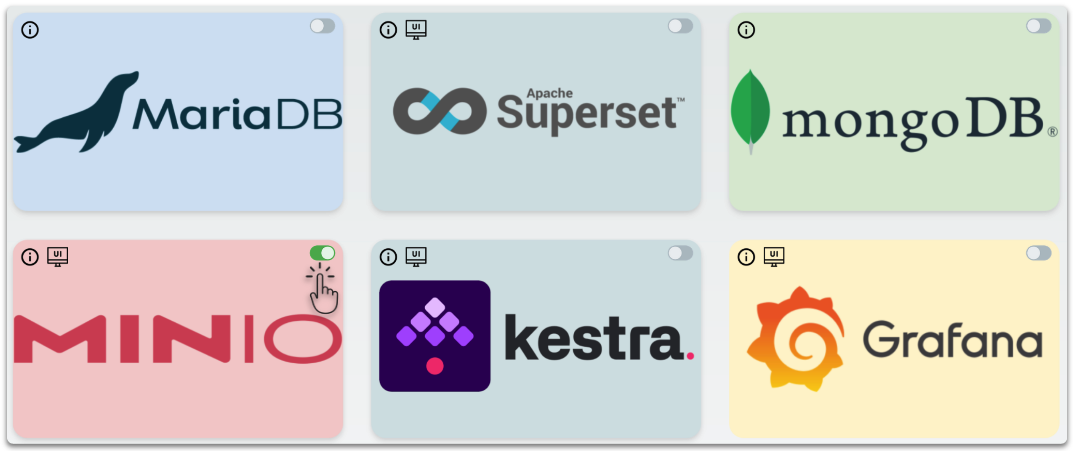

<a id='2'></a>
## Step 1 - Create DataFrame with Bike points information for current month

You can easily create a DataFrame from multiple files ***by using wildcards (*) in the filenames stored in MinIO***. Although more advanced regular expressions can be used for more specific filtering, that is outside the scope of this course.

The filename format has been designed as follows: `bikepoints_yyyyMMdd_hhmm.json`, where:

* **`yyyy`** represents the year
* **`MM`** represents the month
* **`dd`** represents the day
* **`hh`** represents the hour
* **`mm`** represents the minute

Since the data is **partitioned by year, month, day, and hour**, you can use **wildcards to include multiple files**. For example, to load all files for July 2024 (your dates will differ), you could use the following pattern: `bikepoints_202407*_*.json`.

Additionally, you may want to **include a new column in the DataFrame containing the filename associated with each row**. We will not use it in this lab, but it can be useful in certain scenarios.

<a id='2.1'></a>
### DataFrame creation
We need to tell the Spark Session **how to access MinIO**, our *S3-compatible object store*:

In [ ]:
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.access.key", "s3access")
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.secret.key", "_s3access123$")
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.path.style.access", "true")
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem")
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.endpoint", "http://localhost:9000")

We are now ready to **create the DataFrame from the data stored in MinIO**, which will allow us to *begin the Exploratory Data Analysis (EDA)*:

In [ ]:
from pyspark.sql.functions import input_file_name

bikepoint_raw_df = spark_session.read\
                                .json("s3a://raw-data/bikepoints_*.json")

# DataFrame updated with an additional column containing the filename contributing to the data in every row.
bikepoint_raw_df = bikepoint_raw_df.withColumn("filename_path", input_file_name())

# The inferred schema can be visualized using the printSchema() method - definitely semi-structured data.
bikepoint_raw_df.printSchema()

<a id='2.2'></a>
### Shaping the DataFrame to answer business questions
Once your files are available in the batch storage layer, your goals will be:

1. ***Define the logic you need*** to implement in Spark to answer the required business questions.
2. ***Adapt the initial “raw” DataFrame*** to create a structure that simplifies the implementation of that logic. This approach is often called ["Schema on Read"](https://www.geeksforgeeks.org/what-is-schema-on-read-and-schema-on-write-in-hadoop/) and is a very powerful way to make the most of the data stored in your storage layer.
3. ***Translate the logic into Spark code*** that will define your Spark job.

Since the business question we need to answer is ***"What are the minimum, maximum, and average numbers of bikes used during the current month?"***, we need to create a DataFrame containing the following elements:

1. ***The identifier of each Bike Point*** and its name
2. ***The GPS location of each Bike Point***, in case we want to plot the results on a map later
3. ***The number of bikes in use*** per Bike Point over time

In [ ]:
from pyspark.sql.functions import explode

bikepoint_df = bikepoint_raw_df.withColumn("additional", explode("additionalProperties"))\
                               .select("id", "commonName", "lat", "lon",
                                       "additional.key","additional.value","additional.modified")
bikepoint_df.printSchema()

In [ ]:
bikepoint_df.limit(10).toPandas()

<a id='3'></a>
## Step 2 - Temporary view creation



We're going to *simplify the temporary view management* to the following **two functions**:

* **[DataFrame.createOrReplaceTempView()](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.createOrReplaceTempView.html) -** **creates or replaces a local temporary view** with the referenced [DataFrame](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.html). The lifetime of the temporary view is tied to the [SparkSession](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.SparkSession.html) that was used to create the referenced [DataFrame](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.html).
* **[pyspark.sql.Catalog.dropTempView()](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.Catalog.dropTempView.html) -** **drops the local temporary view** with the given view name in the catalog. A Catalog instance is accessible via the **[catalog](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.SparkSession.catalog.html#pyspark.sql.SparkSession.catalog) property** of the [SparkSession](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.SparkSession.html) *we always create at the beginning of our Spark applications*.
* **[pyspark.sql.Catalog.listTables()](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.Catalog.listTables.html#pyspark.sql.Catalog.listTables) -** returns a list of views in the current [SparkSession](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.SparkSession.html).

Let's display the *number of available views* before doing anything:

In [ ]:
spark_session.catalog.listTables()

Let's **create a new view** called `BikePoints` from the `bikepoint_df` [DataFrame](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.html):

In [ ]:
bikepoint_df.createOrReplaceTempView("BikePoints") 

Let's display the *number of available views* after the previous statement:

In [ ]:
spark_session.catalog.listTables()

<a id='3.1'></a>
### Temporary view SQL manipulation
Temporary view SQL manipulation is done via the **following function**:

* **[SparkSession.sql()](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.SparkSession.sql.html#pyspark.sql.SparkSession.sql) -** returns a [DataFrame](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.html) representing the result of the given query.

Let's address the business question we've been challenged with, "***what's the mininum, maximum and average bikes used in the current month?***", using SQL:

In [ ]:
spark_session.sql("""SELECT id, key, MIN(value), MAX(value), AVG(value)
                     FROM BikePoints
                     WHERE key='NbBikes'
                     GROUP BY id,key""")\
             .limit(10)\
             .toPandas() 

<a id='3.2'></a>
### DataFrame from results after temporary view manipulation
**There's nothing special** needed to translate the result of manipulating a temporary view with [SparkSession.sql()](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.SparkSession.sql.html#pyspark.sql.SparkSession.sql) into a [DataFrame](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.html), as the function already returns a [DataFrame](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.html):

In [ ]:
spark_session.sql("""SELECT id, key, MIN(value), MAX(value), AVG(value)
                     FROM BikePoints
                     WHERE key='NbBikes'
                     GROUP BY id,key""")

In [ ]:
spark_session.sql("""SELECT id, key, MIN(value), MAX(value), AVG(value)
                     FROM BikePoints
                     WHERE key='NbBikes'
                     GROUP BY id,key""")\
              .printSchema()

<a id='3.3'></a>
### SQL challenge with Spark SQL
Let's try to answer a more elaborate business question with SQL: "***Display BikePoints with a broken-bike ratio greater than 0% in the currently ingested data***", where *\# of broken bikes = NbDocks-NbBikes-NbEmptyDocks*.

Our Data Engineering team has created the following DataFrame containing the information for `NbBikes`, `NbDocks`, and `NbEmptyDocks`:

In [ ]:
from pyspark.sql.types import IntegerType
import pyspark.sql.functions as F

bikepoint_docks_df = \
  bikepoint_raw_df.withColumn("additional", F.explode("additionalProperties"))\
                  .select("id", "commonName", "lat", "lon",
                          "additional.key", "additional.value", "additional.modified")\
                  .where("key in ('NbBikes','NbDocks','NbEmptyDocks')")

bikepoint_docks_df.limit(5).toPandas()

**[TBD]** Since *the previously created view is no longer valid* for answering this business question, we need to create a new one.

**[TBD]** We're ready to use SQL to answer the business question we've been challenged with: "***Display BikePoints with a broken-bike ratio greater than 0% in the currently ingested data.***"

<a id='4'></a>
## Environment shutdown

Now that we are done working with the dataset, **let’s stop MinIO to release resources** by switching it off:

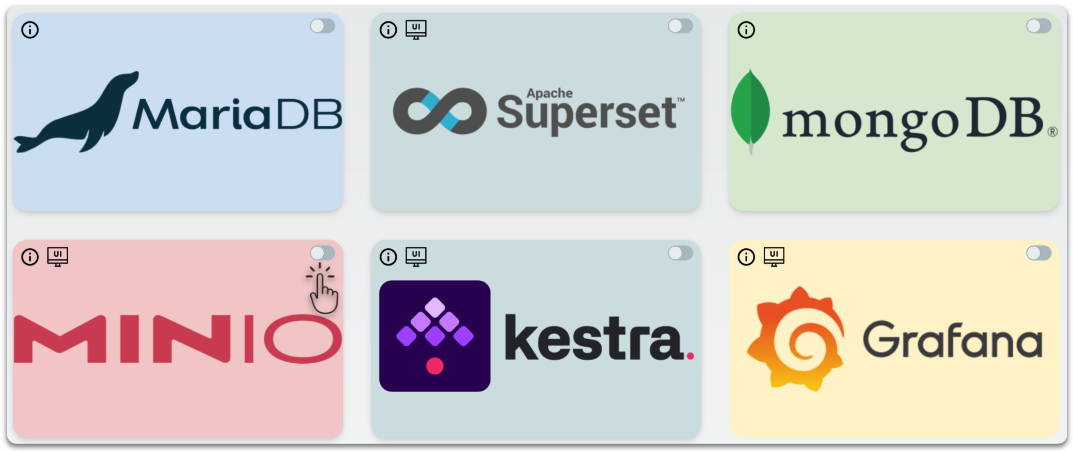

Last but not least, **do not forget to stop your course environment** to release resources and *prevent other applications from being affected or becoming slow*:

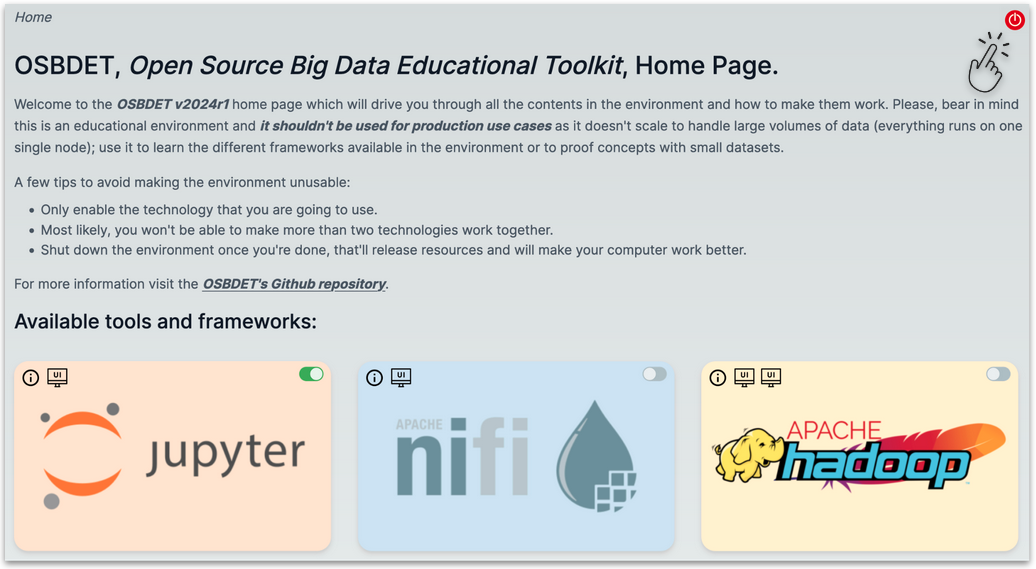